# Structural Collapse at Scale

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Make the repo root (where config.py lives) importable.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from utils.workload_analysis import canonical_plan_graph_signature
from config import GROWTH_CURVE_WORKLOAD_DIR, RESULTS_DIR, FIGURES_DIR

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5,
})

COL_SHAPE = "#6fb2bf"     # muted teal -- matches plan_collision_figure.ipynb's COL_A
COL_COLLAPSE = "#db749e"  # muted mauve -- matches plan_collision_figure.ipynb's COL_B
COL_REF = "#38404d"       # muted slate -- matches tables_2_3_4.ipynb's reference-line gray
INK = "#1f2937"


In [2]:
bundle = json.loads((GROWTH_CURVE_WORKLOAD_DIR / "plans.json").read_text())
plans = bundle["plans"]

failed = [qn for qn, rec in plans.items() if rec["status"] != "ok"]
print(f"{bundle['ok']}/{bundle['query_count']} queries EXPLAINed ok, {len(failed)} failed")
assert not failed, failed

# file-index order (q1, q2, ..., qN) *is* dsqgen generation order (stream-major,
# position-in-stream-minor) -- see generation_report.json.
qnames = sorted(plans.keys(), key=lambda qn: int(qn[1:]))
signatures = [canonical_plan_graph_signature(plans[qn]["dag"]) for qn in qnames]
len(qnames), len(set(signatures))


10815/10815 queries EXPLAINed ok, 0 failed


(10815, 91)

In [3]:
seen_count: dict[str, int] = {}
rows = []
n_collapsed_running = 0
for i, sig in enumerate(signatures, start=1):
    prior = seen_count.get(sig, 0)
    if prior >= 1:
        n_collapsed_running += 1
    seen_count[sig] = prior + 1
    rows.append({
        "n": i,
        "query": qnames[i - 1],
        "distinct_shapes_so_far": len(seen_count),
        "collapsed_so_far": n_collapsed_running,
    })

curve_df = pd.DataFrame(rows)
curve_df["collapse_pct_so_far"] = 100 * curve_df["collapsed_so_far"] / curve_df["n"]

out_csv = RESULTS_DIR / "structural_collapse_growth_curve.csv"
curve_df.to_csv(out_csv, index=False)
print(f"wrote {out_csv} ({len(curve_df)} rows)")
curve_df.iloc[[0, 98, 999, 4999, 9999, -1]]


wrote results/structural_collapse_growth_curve.csv (10815 rows)


,n,query,distinct_shapes_so_far,collapsed_so_far,collapse_pct_so_far
0,1,q1,1,0,0.000000
98,99,q99,83,16,16.161616
999,1000,q1000,90,910,91.000000
4999,5000,q5000,91,4909,98.180000
9999,10000,q10000,91,9909,99.090000
10814,10815,q10815,91,10724,99.158576


In [4]:
checkpoints = curve_df[curve_df["n"].isin([99, 1000, 10000])].copy()
checkpoints["collapse_pct_so_far"] = checkpoints["collapse_pct_so_far"].round(1)
checkpoints = checkpoints.rename(columns={
    "n": "N", "distinct_shapes_so_far": "Distinct Plan Shapes",
    "collapsed_so_far": "Collapsed Queries", "collapse_pct_so_far": "Collapsed (%)",
}).drop(columns="query").set_index("N")
checkpoints


,Distinct Plan Shapes,Collapsed Queries,Collapsed (%)
N,,,
99,83,16,16.2
1000,90,910,91.0
10000,91,9909,99.1


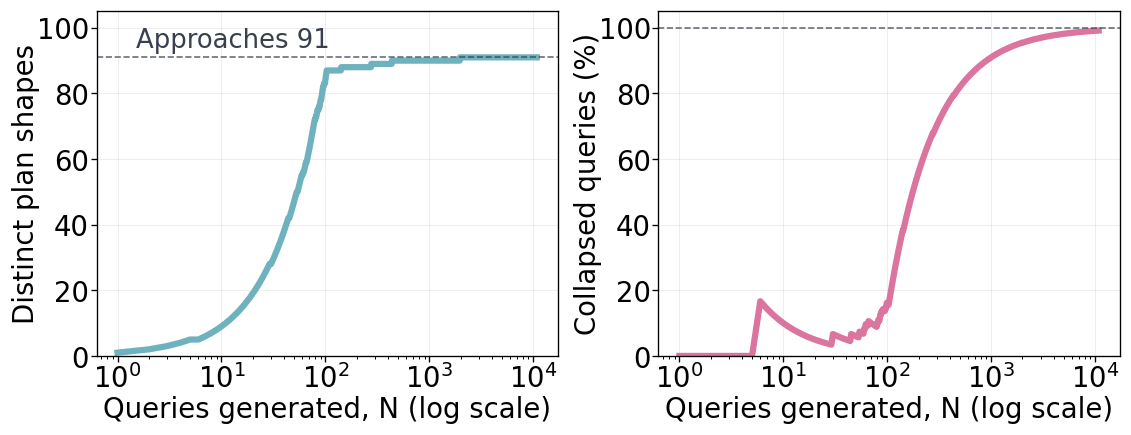

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.7), sharex=True)
ax0, ax1 = axes

font_size = 16.5
line_w = 3.75

n = curve_df["n"].to_numpy()
shapes = curve_df["distinct_shapes_so_far"].to_numpy()

ax0.plot(n, shapes, color=COL_SHAPE, lw=line_w)
ax0.axhline(shapes[-1], color=COL_REF, lw=1, ls="--", alpha=0.75)
ax0.text(1.5, shapes[-1] + 3, f"Approaches {int(shapes[-1])}", fontsize=font_size -1, color=COL_REF)
ax0.set_xscale("log"); ax0.set_ylim(0, 100)
ax0.set_xlabel("Queries generated, N (log scale)", fontsize=font_size, labelpad= 1)
ax0.set_ylabel("Distinct plan shapes", fontsize=font_size, labelpad= -2)

collapse_pct = curve_df["collapse_pct_so_far"].to_numpy()
ax1.plot(n, collapse_pct, color=COL_COLLAPSE, lw=line_w)
ax1.axhline(100, color=COL_REF, lw=1, ls="--", alpha=0.75)
ax1.set_ylim(0, 105); ax0.set_ylim(0, 105)
ax1.set_xlabel("Queries generated, N (log scale)", fontsize=font_size, labelpad= 1)
ax1.set_ylabel("Collapsed queries (%)", fontsize=font_size, labelpad= -2)

ax1.tick_params(axis='x', labelsize=font_size, pad=1)
ax1.tick_params(axis='y', labelsize=font_size, pad=1)
ax0.tick_params(axis='x', labelsize=font_size, pad=1)
ax0.tick_params(axis='y', labelsize=font_size, pad=1)

# Full black box outline (the setup cell's rcParams hide the top/right spines).
for a in (ax0, ax1):
    for spine in a.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "tpcds_structural_collapse_curve.png")
fig.savefig(FIGURES_DIR / "tpcds_structural_collapse_curve.pdf")
plt.show()
